# 01 · Understand and replay the settlement-value strategy

**Beginner tutorial · about 40–55 minutes.** Read notebook 00 first. This lesson
explains the trading idea, inputs, parameters and every output—not just how to
run the code. You can run all cells without changing any settings.

**The question:** with the information available then, what would the actual
`settlement_value` plugin have decided, and what happens under two declared
execution assumptions?

This uses existing local recordings through `Lab` and the strategy replay.
It does not subscribe to a feed or place real orders. The notebook configures
and visualizes the experiment; the strategy logic lives in the plugin.
Choose the project Python kernel and **Restart Kernel and Run All**. The first
load and two runs can take a minute or more; current timings depend on the
implementation and dataset. See [README](README.md) for setup.

**Important labels:** K is provisional, the historical winner is a proxy, and
fills/fees/delays are scenario assumptions. A positive model expectation is
not a guaranteed profit. A negative result on one window is not proof that
every model or setting fails. Read the actual configuration and labels below.

The current loader can write reusable research-cache files under `var/research/strategy_replay/cache`. It does not alter the warehouse.

## 1. The strategy intuition, from zero

In a hypothetical \$1 binary contract, the expected payout of one net Up
share is its probability of winning times \$1. A 75% probability means
expected payout \$0.75; it does not mean a 75% guaranteed return.
Buying at an all-in cost below expected payout may offer positive expected
profit. `settlement_value` holds until resolution rather than requiring a
future trader to offer a profitable resale.

A token priced at 12 cents can still be overpriced. “Cheap” means low
**relative to a defensible probability and costs**, not low in absolute cents.
The strategy may buy Up, buy Down or skip. It does not buy both for safety.

**Inputs and their jobs:**

- **Market metadata and identities:** which window, which tokens, and what
  the rule claims. Outcome-index mapping connects a recorded vector to a token.
- **Opening reference K and current reference:** define the candidate event
  and its present state. Here K is sealed without official attestation.
- **Binance trades:** fast BTCUSDT prices; recent log returns feed volatility.
  The recorded USD reference is a different measurement with different timing.
- **Volatility, sigma:** how uncertain the remaining BTC movement is, estimated
  with more weight on recent returns (EWMA = exponentially weighted moving average).
- **Time remaining, tau:** how much opportunity remains for the relevant
  measurement to move. It is measured in seconds, not the number of trades.
- **Both outcome books:** bid, ask and quantity at each level. Depth limits
  how many shares can be bought before prices get worse.
- **Execution feedback:** pending orders, confirmed net shares and debit.
  This stops duplicate purchases and distinguishes intentions from ownership.

**Signal → action:** probability + uncertainty → fee/depth-adjusted edge
on each side → time/readiness/budget checks → one buy or skip → hold after fill.

If the model's Up range is [0.65, 0.80], its conservative Up probability is
0.65. The corresponding Down range is [0.20, 0.35], so conservative Down is
**1 − 0.80 = 0.20**, not 1 − 0.65. The range covers chosen parameter scenarios,
not all possible model errors.

**Where the rows come from:** `Lab` reads local normalized warehouse data;
the loader supplies warm-up and the selected window. Book reconstruction
produces valid per-socket views, reference/trade observations enter the
runtime, and the real driver is called chronologically. The engine fills
against its arrival-time book and delivers feedback later. Later resolution
rows are labels, not signals. Numeric plotting views do not replace exact
Decimal quantities used in the accounting.

### How four inputs become a probability

The current **endpoint** model asks: if the final price follows a simple
random-movement approximation, how likely is it to finish above K?
Its calculation is:

$$z = \frac{\ln(S/K)}{\sigma\sqrt{\max(\tau,\tau_{floor})}},
\qquad P(Up) = \Phi(z).$$

- **S:** the selected current BTC price; **K:** the opening threshold.
- **ln(S/K):** distance above/below K expressed as a log return, close
  to the percentage change for small moves.
- **sigma × sqrt(time):** the model's scale for the remaining return
  uncertainty. **z** measures the distance in units of that uncertainty.
- **Phi:** the standard bell-curve conversion from this distance to a
  probability. You do not need to calculate it by hand.
- **tau_floor:** the smallest time used in the denominator, preventing
  extreme numerical sensitivity near expiry. Entry has separate time gates.

**Synthetic intuition:** let S = 100.10, K = 100, sigma = 0.0001 per
square-root second and tau = 100 seconds. Distance is approximately
0.1%, remaining uncertainty is 0.1%, so z is about 1 and P(Up) about 84%.
With the same prices but four times as much time, uncertainty doubles,
z is about 0.5 and P(Up) about 69%. More time allows more opportunity
to cross back below K. If S is below K, the probability is below 50%;
if S equals K, this particular model gives 50%.

**Where sigma comes from:** sampled Binance prices become log returns;
the volatility indicator estimates their variation, weighting recent
returns more heavily. It needs warm-up and a minimum sample count.
The floor prevents an unusually quiet sample from implying almost no
uncertainty; it is a modeling choice, not a known physical constant.

This is the formula implemented by the shared fair-value indicator, not
a verified law of BTC. It has no separate directional-drift term.
In particular, an endpoint probability is not automatically a probability
for a **60-second average**. Notebook 00 explains why that distinction
matters; a more confident endpoint number cannot resolve it.

### Worked example: expected value is not realized profit

This **synthetic example** uses a hypothetical \$1 payout, a chosen 75% win
probability, 10 gross shares at 70 cents, and an explicit scenario fee curve.
It is not recorded performance or the notebook's five-unit budget.

Under a share-denominated buy fee, part of the purchased quantity is deducted:
cash debit is `gross × price`; payout-bearing shares are fewer than gross.
Expected profit is `probability × net shares − debit`.
All shares share the same outcome, so buying more does not diversify this bet.

Synthetic scenario, not historical fees or observed returns
Gross / fee / net shares: 10 0.2100 9.7900
Debit: 7.00 Expected profit: 0.342500


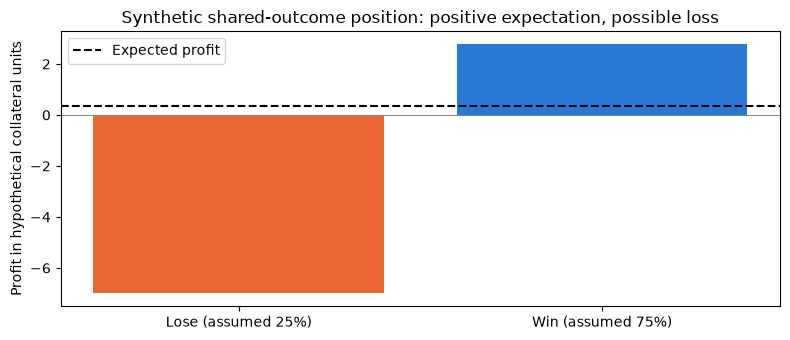

In [1]:
from decimal import Decimal

import matplotlib.pyplot as plt

from tyrex_pm.domain.polymarket.fees import FeeCurveParams, phi_taker_fee_per_share

toy_price, toy_gross, toy_q = Decimal("0.70"), Decimal("10"), Decimal("0.75")
toy_fee = phi_taker_fee_per_share(
    toy_price, FeeCurveParams(fee_rate=Decimal("0.07"), exponent=Decimal("1"))
)
toy_fee_shares = toy_gross * toy_fee / toy_price
toy_net = toy_gross - toy_fee_shares
toy_debit = toy_gross * toy_price
toy_ev = toy_q * toy_net - toy_debit
print("Synthetic scenario, not historical fees or observed returns")
print("Gross / fee / net shares:", toy_gross, toy_fee_shares, toy_net)
print("Debit:", toy_debit, "Expected profit:", toy_ev)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(["Lose (assumed 25%)", "Win (assumed 75%)"],
       [float(-toy_debit), float(toy_net - toy_debit)], color=["#eb6834", "#2a78d6"])
ax.axhline(float(toy_ev), color="black", linestyle="--", label="Expected profit")
ax.axhline(0, color="gray", linewidth=0.7)
ax.set(title="Synthetic shared-outcome position: positive expectation, possible loss",
       ylabel="Profit in hypothetical collateral units")
ax.legend()
fig.tight_layout()

**Read the example:** fee is 0.21 shares, leaving 9.79 net shares. Debit is
7 units; expectation is +0.3425. The single result is either −7 or +2.79,
not necessarily +0.3425. Expected value is an average over hypothetical
repetitions **if the assumed probability were correct**.

**Now load the actual catalog.** The next printed count filters for windows
lying inside the recording with warm-up. It does not certify uninterrupted
coverage or official settlement semantics. `market_id` is displayed only by
its last characters for readability; full identities remain in the results.

In [2]:
import pandas as pd

from tyrex_pm.research.strategy_lab import frames, plots
from tyrex_pm.research.strategy_lab.experiments import Lab

pd.set_option('display.width', 160)

lab = Lab()
windows = lab.windows()
print(f'{len(windows)} windows fully inside the recording (with warm-up)')
pd.DataFrame([{'slug': w.slug, 'market_id': w.market_id[-12:]} for w in windows]).head()

58 windows fully inside the recording (with warm-up)


,slug,market_id
0,btc-updown-5m-1791297900,0923be1d1dc4
1,btc-updown-5m-1791298200,63a2d984bdf2
2,btc-updown-5m-1791298500,7e3ff64d6dad
3,btc-updown-5m-1791298800,3320b360da3f
4,btc-updown-5m-1791299100,32fd45895f6d


## 2. Choose the window and understand the parameters

`WINDOW` selects a particular recorded market. Its existing suffix selection
reproduces the M1 example; it is a chosen teaching case, not a random sample or
an untouched holdout. If using another collection, choose an available ID from
the catalog above rather than assuming this suffix exists.

`PARAMETERS` contains **overrides**, not the entire configuration. The plugin
supplies defaults; `Lab.run` also explicitly accepts provisional K for research.
Strings such as `'0.02'` represent exact decimal quantities; values such as
`0.25` are model settings. We display the expanded configuration after the run.

**Parameters used in this example:**

- `model.spot_input = binance_spot`: S is the latest raw Binance BTCUSDT price.
  K comes from the recorded USD TWAP reference. This intentionally combines
  different measurements and quote currencies without a raw-spot USD/USDT
  correction, so the endpoint forecast is a proxy. `aligned_reference` instead
  uses the host's reference-aligned estimate; it is not proof of an official
  payoff model either.
- `model.sigma_band = 0.25`: re-evaluate probability with volatility around
  its point estimate, including ±25%. This is a sensitivity band, not a 25%
  probability error or a statistically guaranteed confidence interval.
- `entry.tau_min_s = 30`, `tau_max_s = 240`: buy only with 30–240 seconds left.
  In a 300-second window, that excludes the first minute and last 30 seconds.
  These are entry restrictions, not a rule to sell at 30 seconds.
- `entry.min_edge_per_share = '0.02'`: require at least 2 cents of conservative
  marginal expected profit per **gross** share at each price level used, with
  the selected fee treatment. It is not a 2% BTC move or a guaranteed gain.
- `entry.target_mode = cap_only`: use a feasible budget-constrained size even
  when its expected profit is below \$3. `require_target` would instead skip
  when the configured expected-profit target is infeasible.
- `sizing.max_debit_usdc = '5'`: cap modeled acquisition debit at 5 collateral
  units. This is different from the replay's starting cash and from a profit target.

**Other defaults worth inspecting:** EWMA half-life (how fast old returns lose
weight), minimum warm-up, sampling interval, sigma floor (minimum modeled
volatility), reference uncertainty in basis points, maximum loss, displayed-depth
participation, maximum book levels, share increment and fallback minimum size.
Scenario participation is a separate assumption about actual simulated fills.

A **basis point** is 0.01%; 100 bps = 1%. Sigma is log-return volatility per
square-root second, not a token price or BTC dollar amount. In the endpoint
approximation, remaining return uncertainty scales like `sigma * sqrt(tau)`.
A volatility floor can therefore materially affect probabilities.

**Read the next cell:** each `lab.run` creates a fresh strategy/replay state.
Both scenarios share the window and strategy parameters. They can still yield
different decisions because information arrives at different simulated times.

**Model selection:** this lesson explicitly selects `endpoint_diffusion`.
The project also has a `twap_proxy_diffusion` backend. It uses a different
forecast and still has proxy assumptions; its existence does not change
the meaning of the endpoint formula taught here.

**Changing defaults:** volatility is not overridden in `PARAMETERS`, so
read its effective settings below. The current floor is a research seed;
an older saved M1 result used a higher floor and can produce a different
entry. Never compare changed-default runs as if only execution changed.

**Limit buffer:** `entry.limit_buffer_ticks` permits the buy limit to sit
above the last price level used for planned sizing, within the strategy's
safeguards. With zero ticks the limit is tight. A larger buffer can allow
worse actual fills; the forecast shown at the decision uses planned walk
prices, so inspect actual debit and net shares afterward. This lesson
leaves the buffer at its default; it is not an instruction to widen it.


In [3]:
WINDOW = next(w for w in windows if w.market_id.endswith('f241'))   # 2026-10-06 17:50-17:55 UTC
PARAMETERS = {
    'model': {'backend': 'endpoint_diffusion', 'spot_input': 'binance_spot',
              'sigma_band': 0.25},
    'entry': {'tau_min_s': 30, 'tau_max_s': 240, 'min_edge_per_share': '0.02',
              'target_mode': 'cap_only'},
    'sizing': {'max_debit_usdc': '5'},
}
results = {name: lab.run(WINDOW.market_id, parameters=PARAMETERS, scenario=name)
           for name in ('favorable', 'friction')}
pd.DataFrame([frames.summary(r) for r in results.values()]).set_index('scenario').T

scenario,favorable,friction
slug,btc-updown-5m-1791309000,btc-updown-5m-1791309000
winner,UP,UP
label_type,proxy_outcome,proxy_outcome
entered,False,False
filled,False,False
side,None,None
entry_tau_s,None,None
p_conservative,None,None
book_implied_up_at_entry,None,None
limit_price,None,None


### Read the summary before the charts

`entered` means an order was generated, not that it filled. `filled` is a
separate fact. `side` names the selected/acquired outcome; `entry_tau_s`
is seconds remaining at the decision. `limit_price` is the highest permitted
buy price, while `vwap` is the volume-weighted average **simulated fill** price.

`debit` is cash spent, `fill_ratio` is gross filled / intended quantity, and
`ev_conservative` is the forecast for the intended position. A partial fill
can make the acquired exposure smaller than that forecast. `realized_pnl`
here is retrospective **proxy payout minus simulated debit**, not a real
credited balance. No fill can produce `None`/`NaN`, not a measured trading
loss. `limitations` qualify interpretation; `digest` identifies comparable
decisions and economics for reproducibility, not strategy quality.

**Inspect the expanded strategy settings:** the next cell combines plugin
defaults, research K acceptance and this notebook's overrides. Scenario
execution settings are separate and follow afterward.

In [4]:
from tyrex_pm.research.strategy_lab.experiments import RESEARCH_BASE_PARAMETERS, merge
from tyrex_pm.strategies.settlement_value.schema import (
    settlement_value_config_as_parameters,
    settlement_value_config_from_parameters,
)

expanded_config = settlement_value_config_as_parameters(
    settlement_value_config_from_parameters(merge(RESEARCH_BASE_PARAMETERS, PARAMETERS))
)
pd.DataFrame([
    {"parameter": f"{section}.{key}", "effective_value": str(value)}
    for section, settings in expanded_config.items()
    for key, value in settings.items()
]).set_index("parameter")

,effective_value
parameter,
settlement.functional_id,reference_at_close_vs_open
settlement.comparison,AT_OR_ABOVE_K
settlement.reference_series,chainlink:btcusd:twap:60
settlement.reference_units,USD
settlement.timestamp_meaning,provider_source_time
settlement.provenance_status,ASSUMED
settlement.evidence,[]
model.backend,endpoint_diffusion
model.averaging_window_s,60.0


### Say the result in ordinary language

This next output describes the **current** experiment, rather than
hardcoding what happened in an older version. Read its forecast and
its simulated outcome as separate numbers. The conservative forecast
remains conditional on the chosen model and parameter band.

In [5]:
for scenario_name, result in results.items():
    report = frames.summary(result)
    print(f"\n{scenario_name.upper()}: proxy winner = {report['winner']}")
    if not report["entered"]:
        print("The strategy did not request a purchase. Inspect the reason counts.")
        continue
    print(f"Requested {report['side']} with {report['entry_tau_s']:.1f} seconds left.")
    print(f"Buy limit: {report['limit_price']} collateral units per share.")
    print(f"Conservative forecast for intended purchase: {report['ev_conservative']}.")
    if report["filled"]:
        print(f"A simulated fill occurred; acquisition debit = {report['debit']}.")
        print(f"Retrospective proxy payout minus debit = {report['realized_pnl']}.")
    else:
        print("No simulated fill: this is not a losing filled trade.")
    print(f"Recorded limitations: {report['limitations']}")


FAVORABLE: proxy winner = UP
The strategy did not request a purchase. Inspect the reason counts.

FRICTION: proxy winner = UP
The strategy did not request a purchase. Inspect the reason counts.


## 3. Understand the execution scenarios actually used

`favorable` and `friction` are **assumptions**, not observed fills and not two
historical markets. Read the values printed below rather than memorizing defaults:

- `feed_delay_ms`: additional wait before a recorded observation becomes visible
  to the strategy. It does not delay the replay's market-truth book.
- `decision_delay_ms`: configured decision/processing delay.
- `order_delay_ms`: wait from the decision/submission path to venue arrival.
- `feedback_delay_ms`: wait before a fill/rejection becomes visible to the strategy.
- `adverse_price_ticks`: assumed worse execution in units of the market's price
  increment. A buy can never pay beyond its limit; it can remain unfilled instead.
- `participation`: fraction of displayed liquidity available for simulated fills.
  It is not the strategy's win probability.
- `timer_interval_ms`: how often timer checks may occur on the virtual clock.
- `fee_provenance`: whether the fee parameters are assumptions or supported evidence.

Zero extra delay is generous, but the recording already contains its collector's
receive timing. `favorable` is not a mathematical upper bound. In `friction`,
an adverse tick may push all available prices beyond a tight limit, giving no
fill by construction. That result teaches us about limits, not real queue skill.

In [6]:
keys = ['feed_delay_ms', 'decision_delay_ms', 'order_delay_ms', 'feedback_delay_ms',
        'adverse_price_ticks', 'participation', 'timer_interval_ms']
pd.DataFrame({
    name: {k: r['scenario'][k] for k in keys}
    | {'fee_provenance': r['engine']['fee_provenance']}
    for name, r in results.items()
})

,favorable,friction
feed_delay_ms,0,100
decision_delay_ms,0,0
order_delay_ms,0,300
feedback_delay_ms,0,300
adverse_price_ticks,0,1
participation,1,0.25
timer_interval_ms,1000,1000
fee_provenance,SCENARIO_ASSUMPTION_NOT_VERIFIED_HISTORICAL_FEES,SCENARIO_ASSUMPTION_NOT_VERIFIED_HISTORICAL_FEES


## 4. Read the favorable four-panel chart

**Shared horizontal axis:** seconds **remaining** until the scheduled close.
Read left to right: larger numbers are earlier, zero is close. At 300 the
five-minute window opens; values above 300 are pre-window warm-up. The vertical
aqua dashed line, when present, marks the **entry decision**, not proof of a fill.
If no entry was generated, there is no such marker; this is expected.

**Panel 1 — reference prices and K.** Compare the fast Binance series, the
recorded Chainlink TWAP series and the horizontal provisional threshold.
A gap between spot and TWAP may reflect smoothing/lag as well as quote currency.
The chart's USD label is shorthand: Binance is USDT/BTC, reference is USD/BTC;
no FX conversion is performed here. A higher line is not automatically an edge.

**Panel 2 — probability.** Blue is model P(Up); shading is the configured
parameter-sensitivity range. Orange is the Up-book midpoint used as a probability
baseline, not a measured true probability or an executable purchase price.
At 0.70 read “70% under this estimate,” not “70 dollars.” If the model is below
the book, it gives Down more probability than the book baseline does. That
disagreement is a candidate signal, not evidence that the model is right.

**Panel 3 — outcome books.** Ask is what an immediate buyer faces; bid is what
an immediate seller faces. Their difference is the spread. Read actual Up and
Down books separately: a Down ask is not necessarily one minus the Up ask.
The BUY marker is the intended order and its maximum price, not a fill marker.
Check the ledger later for whether and how much was acquired.

**Panel 4 — decision reasons.** Each dot is an evaluation. Rows are categories,
not ranked scores. Many HOLD dots mean repeated checks while holding one
position, not many trades or independent experiments. Probability can remain
plotted after entry even though the strategy cannot open another episode.

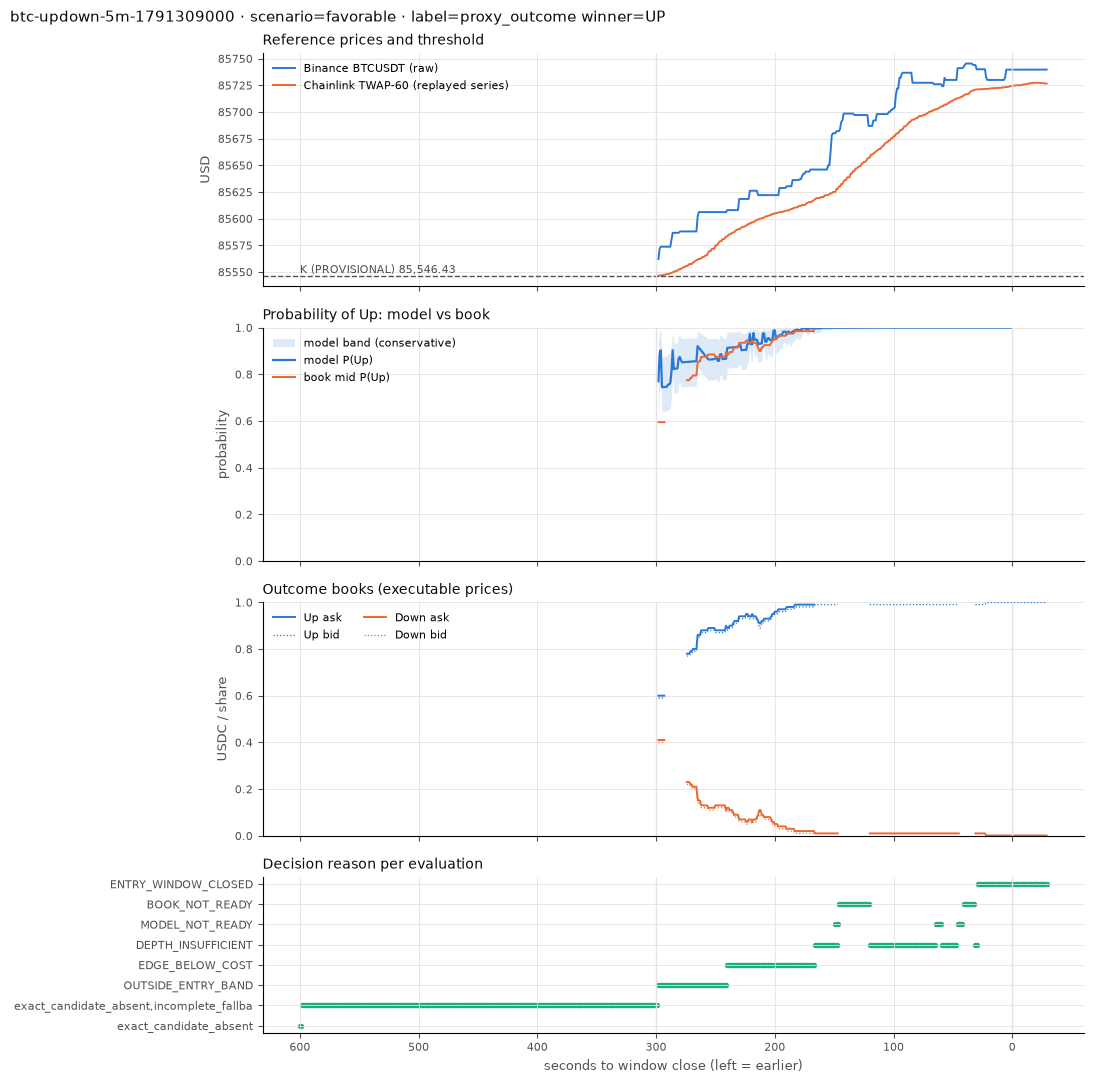

In [7]:
fig = plots.plot_window(results['favorable'])

## 5. Read the friction chart using the same questions

If there is an intended buy, locate it and ask whether a fill actually followed.
If both scenarios generated no entry, they do not compare fill quality: there
was no order to execute under either set of assumptions. Information
delay can move the decision time; order delay changes the book encountered;
participation and limits change fill quantity. The outcome of the historical
market is unchanged by our execution scenario.

Compare the two charts by time, side, limit and reasons. A BUY marker with no
owned inventory is a valid no-fill experiment. It must not be interpreted as a
losing filled trade or secretly filled at a price beyond the limit.

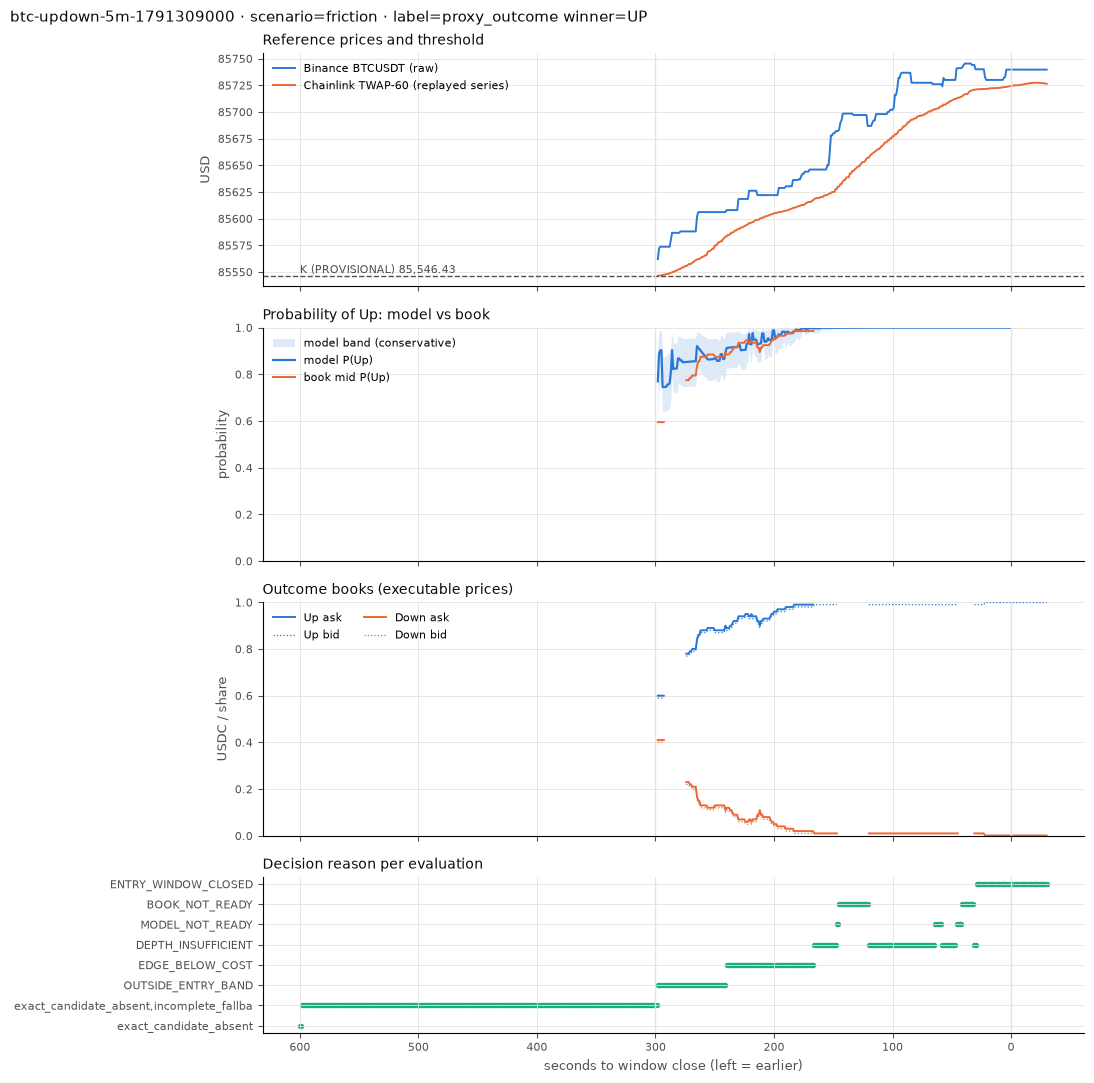

In [8]:
fig = plots.plot_window(results['friction'])

## 6. Follow the decision trail, not only the buy

**Actual logic, in words:**

1. If an attempt is already consumed or inventory exists, do not buy again;
   request/maintain holding after confirmed execution feedback.
2. Otherwise check time, accepted K quality, reference, volatility and books.
3. Estimate probability and its sensitivity band.
4. For each side, walk affordable ask levels while conservative marginal edge
   passes the minimum. Choose the feasible side with the highest conservative
   expected profit (then deterministic tie-breaks), or do nothing.
5. Emit at most one entry intent. A partial or failed attempt does not authorize
   buying again in this initial one-attempt implementation.

`ENTER` is a recommendation; `WAIT` means not now; `SKIP` means an entry condition
such as the remaining-time band is no longer satisfied; `BLOCKED` indicates a
readiness/risk blocker; `HOLD` maintains the existing acquired position.

Typical reasons: `MODEL_NOT_READY` (volatility/input not usable), `K_MISSING` or
`K_NOT_ACCEPTED`, `BOOK_NOT_READY`, `EDGE_BELOW_COST`, `TARGET_INFEASIBLE`,
`PENDING_ORDER`, `EPISODE_CONSUMED`, and `HOLDING_TO_SETTLEMENT`.
The counts below count **evaluations**, not trades, seconds or win rates.

A few chart codes deserve special attention: `DEPTH_INSUFFICIENT` means
no feasible purchase quantity was available under the sizing constraints;
`ENTRY_WINDOW_CLOSED` means too little time remains for a new entry.
Some early reasons come from the host preparing the opening threshold, before
the trading model is ready. Chart labels may be shortened; use the full reason
counts below to read them. A readiness message is not an executed trade.

In [9]:
for name, r in results.items():
    print(f'--- {name}')
    print(frames.reasons(r).to_string())

--- favorable
action        reason                                               
HOST_SKIPPED  exact_candidate_absent,incomplete_fallback_candidates    300
WAIT          DEPTH_INSUFFICIENT                                        89
              EDGE_BELOW_COST                                           74
SKIP          ENTRY_WINDOW_CLOSED                                       59
WAIT          OUTSIDE_ENTRY_BAND                                        58
              BOOK_NOT_READY                                            36
              MODEL_NOT_READY                                           12
HOST_SKIPPED  exact_candidate_absent                                     2
--- friction
action        reason                                               
HOST_SKIPPED  exact_candidate_absent,incomplete_fallback_candidates    300
WAIT          DEPTH_INSUFFICIENT                                        89
              EDGE_BELOW_COST                                           74
SKIP        

In [10]:
d = frames.decisions(results['favorable'])
cols = ['t_minus_s', 'action', 'reason', 'reference_price', 'k', 'sigma', 'p_up_point',
        'p_up_low', 'p_up_high', 'book_implied_up', 'up_ask', 'down_ask',
        'up_first_level_edge', 'down_first_level_edge']
d[d['action'].isin(['ENTER', 'WAIT'])][[c for c in cols if c in d]].head(15)

,t_minus_s,action,reason,reference_price,k,sigma,p_up_point,p_up_low,p_up_high,book_implied_up,up_ask,down_ask,up_first_level_edge,down_first_level_edge
302,298.0,WAIT,OUTSIDE_ENTRY_BAND,85562.01,85546.427056,0.000014,0.770275,0.605216,0.936723,0.595,0.6,0.41,-0.011730,-0.349336
303,297.0,WAIT,OUTSIDE_ENTRY_BAND,85572.01,85546.427056,0.000014,0.888092,0.741403,0.984780,0.595,0.6,0.41,0.120644,-0.395409
304,296.0,WAIT,OUTSIDE_ENTRY_BAND,85573.66,85546.427056,0.000014,0.902697,0.761653,0.988479,0.595,0.6,0.41,0.140327,-0.398955
305,295.0,WAIT,OUTSIDE_ENTRY_BAND,85573.67,85546.427056,0.000028,0.744804,0.641022,0.875597,0.595,0.6,0.41,0.023074,-0.290735
306,294.0,WAIT,OUTSIDE_ENTRY_BAND,85573.66,85546.427056,0.000028,0.745085,0.641179,0.875932,0.595,0.6,0.41,0.023226,-0.291056
307,293.0,WAIT,OUTSIDE_ENTRY_BAND,85573.67,85546.427056,0.000028,0.745523,0.641482,0.876401,0.595,0.6,0.41,0.023521,-0.291506
308,292.0,WAIT,OUTSIDE_ENTRY_BAND,85573.67,85546.427056,0.000028,0.745886,0.641714,0.876805,NaN,NaN,NaN,NaN,NaN
309,291.0,WAIT,OUTSIDE_ENTRY_BAND,85573.66,85546.427056,0.000028,0.746172,0.641874,0.877144,NaN,NaN,NaN,NaN,NaN
310,290.0,WAIT,OUTSIDE_ENTRY_BAND,85573.67,85546.427056,0.000027,0.755992,0.648224,0.887817,NaN,NaN,NaN,NaN,NaN
311,289.0,WAIT,OUTSIDE_ENTRY_BAND,85573.67,85546.427056,0.000027,0.756368,0.648468,0.888217,NaN,NaN,NaN,NaN,NaN


**Reading the decision columns:** `p_up_point/low/high` describe the Up
model range; `book_implied_up` is its midpoint baseline; `up_ask/down_ask`
are separate purchase prices. `reference_price` is the selected model S
and can therefore be raw Binance—not necessarily the official reference.
`sigma` is the scaled volatility used by the model.

`up_first_level_edge/down_first_level_edge` are conservative expected
profits per gross share at the best ask, after the selected share fee.
They are not guaranteed returns. Multiplying by any arbitrary size ignores
deeper prices and budget constraints. The first 15 rows above may be only
WAITs; use the next output to inspect actual ENTER recommendations.

In [11]:
for scenario_name, result in results.items():
    decision_frame = frames.decisions(result)
    entries = decision_frame[decision_frame["action"] == "ENTER"]
    print(scenario_name, "entry recommendations:", len(entries))
    if not entries.empty:
        selected_columns = [c for c in cols if c in entries]
        print(entries[selected_columns].to_string(index=False))
    else:
        print("No entry recommendation; read the reason counts instead.")

favorable entry recommendations: 0
No entry recommendation; read the reason counts instead.
friction entry recommendations: 0
No entry recommendation; read the reason counts instead.


## 7. Orders, fills, fees and the retrospective outcome

The **ledger** is the event diary. `arrived` means the simulated venue received
the order; `fill` means some quantity matched; `unfilled_cancelled` means the
unfilled remainder disappeared; `rejected` means no valid execution;
`payout_receivable` is retrospective payout accounting, not proof of bankable cash.

The order is **FAK**, fill-and-kill: buy what is available immediately within
the limit and cancel the rest. A partial fill is a smaller position, not a
request to top up. The strategy sees fills only after configured feedback delay.

Read `quantity` as gross matched shares and `net_quantity` as payout-bearing
shares after a share-denominated buy fee. Monetary results here use the replay's
collateral accounting; they are not real charged fees or real redemption receipts.

In [12]:
events = ('arrived', 'fill', 'unfilled_cancelled', 'rejected', 'payout_receivable')
for name, r in results.items():
    print(f"--- {name}  label={r['label']['label_type']} winner={r['label']['winner']}  "
          f"limitations={r['engine']['limitations']}")
    ledger = pd.DataFrame([e for e in r['engine']['ledger'] if e['event'] in events])
    if ledger.empty:
        print('(no orders)')
    else:
        print(ledger.drop(columns=[c for c in ('intent', 'model') if c in ledger]).to_string())

--- favorable  label=proxy_outcome winner=UP  limitations=[]
(no orders)
--- friction  label=proxy_outcome winner=UP  limitations=[]
(no orders)


## 8. Interpret this experiment without overclaiming

Follow the current outputs in this order:

1. Was there an entry recommendation? If not, inspect the binding reasons.
2. Which side and conservative probability justified it? Compare with that
   side's actual asks and fee-adjusted expected payout, not just the Up midpoint.
3. Did the order fill, partially fill or remain unfilled? Read actual quantities.
4. What was the proxy winner? Separate model expectation before entry from the
   one realized proxy outcome afterward.
5. Which limitations affected the path? `gap_with_exposure` means a book became
   unusable while exposure existed. A number printed next to a limitation is
   not automatically a qualified result. Inspect rather than hide those paths.

A model assigning 30% to Down expects Down to lose often. Losing this window
alone cannot establish that 30% was wrong. Likewise a profitable trade does
not establish calibration. An unfilled friction order measures neither.

The current endpoint backend with raw Binance spot is a proxy for a potentially
averaged-reference payoff. Investigate averaging/lag, the volatility floor,
uncertainty, execution limits and more windows before selecting settings.
Qualified settlement results require established semantics and payout units.

## 9. Small exercises and the next research question

**Explain before editing:**

1. If model P(Up) = 0.67 and Up's midpoint is 0.88, which side appears
   relatively cheaper to the model? Does that establish an edge?
2. Does a BUY marker prove ownership? What proves a fill in this notebook?
3. Why can widening the maximum price improve fills but reduce expected profit?
4. What is the difference between the five-unit debit cap and the \$3 target?
5. Why are hundreds of evaluation dots still only one market outcome?

**Suggested answers:** (1) Down may be the candidate, but its conservative
probability, actual ask, costs and model validity still matter. (2) No;
simulated fill events and net quantity establish simulated ownership.
(3) More prices become executable, including less attractive ones.
(4) The cap limits expenditure; the target describes forecast profit and
may be infeasible. (5) Repeated observations share the same event and outcome.

**Optional one-change experiment:** copy the notebook, increase only
`entry.min_edge_per_share`, then restart and run all. Predict whether entries
or size can decrease. Compare decisions and quantities, not just final PnL.
Keeping the same result is informative too. This is sensitivity exploration,
not a parameter-selection recommendation.

**Research progression:** verify the data meaning; compare model variants;
test modest execution changes; then study many windows with earlier/later
splits. Do not repeatedly optimize this selected example or treat a holdout
as another tuning set. Live execution and a real holding/redemption lifecycle
are separate engineering and operator gates; this notebook does not run them.